In [2]:
from google.colab import files
uploaded = files.upload()

Saving Unconfirmed 667745.crdownload to Unconfirmed 667745 (1).crdownload


In [3]:
import pandas as pd

df = pd.read_csv('Unconfirmed 667745.crdownload')

In [4]:
print(df.shape)

(1344126, 11)


In [5]:
df.columns

Index(['step', 'type', 'amount', 'nameOrig', 'oldbalanceOrg', 'newbalanceOrig',
       'nameDest', 'oldbalanceDest', 'newbalanceDest', 'isFraud',
       'isFlaggedFraud'],
      dtype='object')

In [6]:
df['type'].value_counts()


,count
type,
CASH_OUT,479577
PAYMENT,450012
CASH_IN,294000
TRANSFER,111565
DEBIT,8972


In [7]:
df.describe()

,step,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
count,1.344126e+06,1.344126e+06,1.344126e+06,1.344126e+06,1.344125e+06,1.344125e+06,1.344125e+06,1344125.0
mean,4.984716e+01,1.632539e+05,8.722173e+05,8.929445e+05,9.889451e+05,1.119676e+06,1.166558e-03,0.0
std,4.539804e+01,2.721806e+05,2.963283e+06,2.999608e+06,2.305812e+06,2.415113e+06,3.413500e-02,0.0
min,1.000000e+00,1.000000e-01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.0
25%,1.600000e+01,1.301550e+04,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.0
50%,3.600000e+01,7.916258e+04,1.542600e+04,0.000000e+00,1.320362e+05,2.262270e+05,0.000000e+00,0.0
75%,4.600000e+01,2.193330e+05,1.294098e+05,1.712260e+05,9.344176e+05,1.159892e+06,0.000000e+00,0.0
max,1.370000e+02,1.000000e+07,3.893942e+07,3.894623e+07,4.220740e+07,4.220740e+07,1.000000e+00,0.0


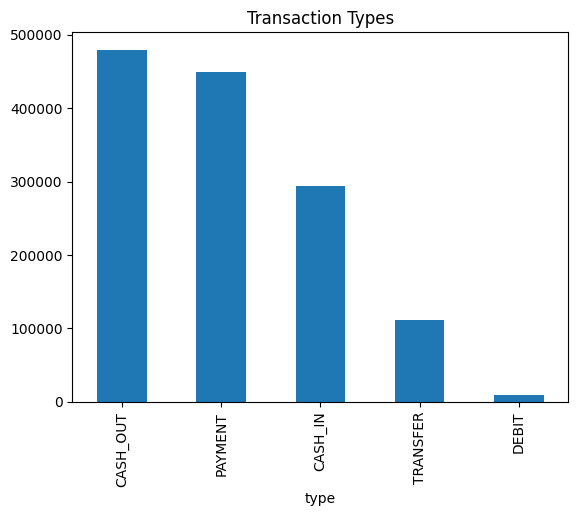

In [8]:
import matplotlib.pyplot as plt

df['type'].value_counts().plot(kind='bar')
plt.title('Transaction Types')
plt.show()

In [9]:
# Group by 'type' and calculate the mean of 'isFraud', then multiply by 100
fraud_rates = df.groupby('type')['isFraud'].mean() * 100

# Sort them so the highest fraud rates are at the top
fraud_rates = fraud_rates.sort_values(ascending=False)

print("Fraud Percentage per Transaction Type:")
print(fraud_rates)

Fraud Percentage per Transaction Type:
type
TRANSFER    0.696455
CASH_OUT    0.164937
CASH_IN     0.000000
DEBIT       0.000000
PAYMENT     0.000000
Name: isFraud, dtype: float64


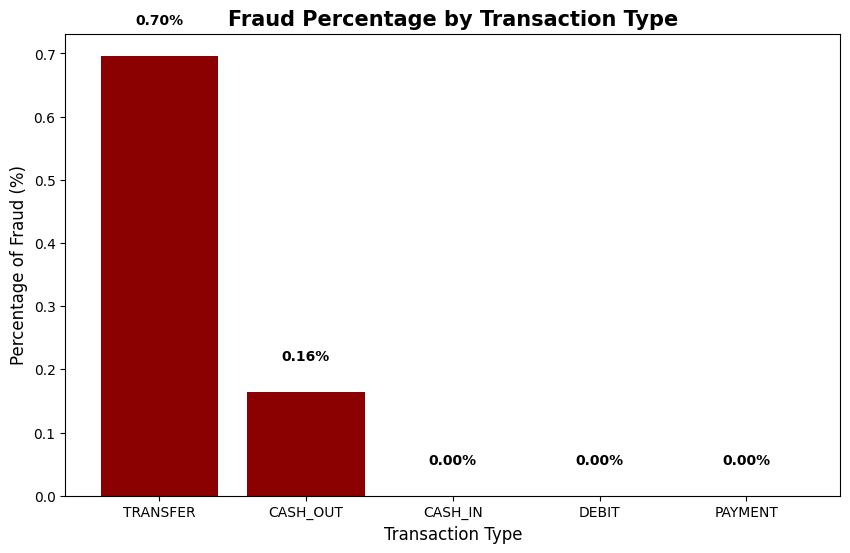

In [10]:
import matplotlib.pyplot as plt

# 1. Calculate the percentage
fraud_percentage = df.groupby('type')['isFraud'].mean() * 100

# 2. Sort the data (optional, makes the chart easier to read)
fraud_percentage = fraud_percentage.sort_values(ascending=False)

# 3. Create the plot
plt.figure(figsize=(10, 6))
plt.bar(fraud_percentage.index, fraud_percentage.values, color='darkred')

# 4. Add labels and title
plt.title('Fraud Percentage by Transaction Type', fontsize=15, fontweight='bold')
plt.xlabel('Transaction Type', fontsize=12)
plt.ylabel('Percentage of Fraud (%)', fontsize=12)

# 5. Add the exact percentage value on top of each bar
for i, v in enumerate(fraud_percentage.values):
    plt.text(i, v + 0.05, f"{v:.2f}%", ha='center', fontweight='bold')

plt.show()

This chart shows fraud only happens in TRANSFER and CASH_OUT transactions — 0.70% and 0.16% respectively — while CASH_IN, DEBIT, and PAYMENT have zero fraud cases. This tells us the model should pay special attention to transaction type

In [11]:
len(df)

1344126

In [12]:
df['isFraud'].value_counts()


,count
isFraud,
0.0,1342557
1.0,1568


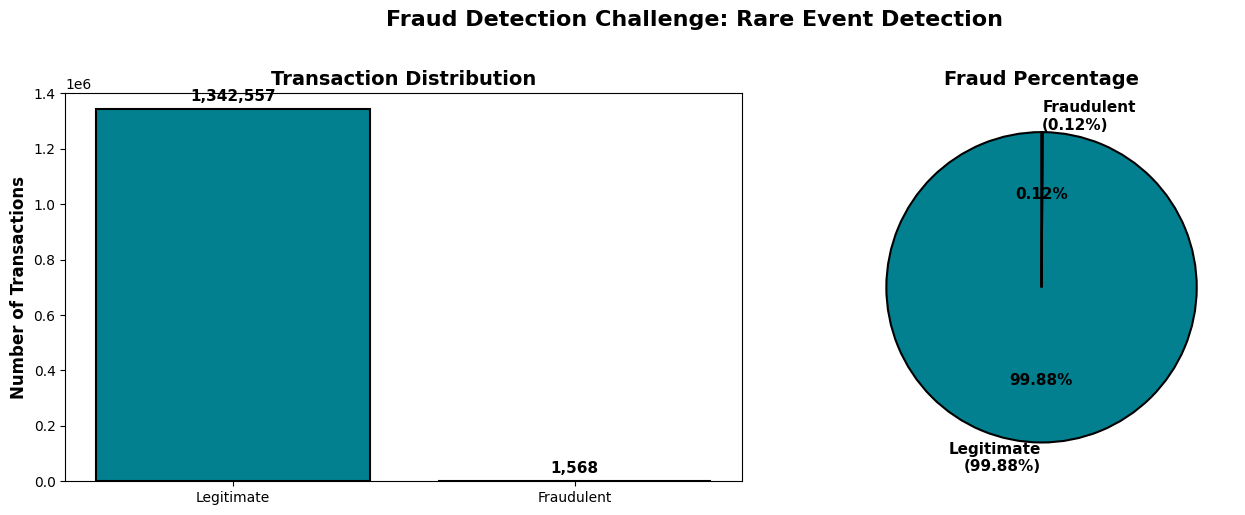

✓ Image saved as: fraud_distribution.png


In [13]:
import matplotlib.pyplot as plt
import numpy as np

# Get fraud distribution
fraud_counts = df['isFraud'].value_counts().sort_index()

# Create figure with 2 subplots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# ===== SUBPLOT 1: BAR CHART =====
categories = ['Legitimate', 'Fraudulent']
values = [fraud_counts[0], fraud_counts[1]]
colors = ['#028090', '#F96167']  # Teal and Red

ax1.bar(categories, values, color=colors, edgecolor='black', linewidth=1.5)
ax1.set_ylabel('Number of Transactions', fontsize=12, fontweight='bold')
ax1.set_title('Transaction Distribution', fontsize=14, fontweight='bold')
ax1.set_ylim([0, 1400000])

# Add value labels on bars
for i, v in enumerate(values):
    ax1.text(i, v + 30000, f'{v:,}', ha='center', fontweight='bold', fontsize=11)

# ===== SUBPLOT 2: PIE CHART =====
labels = ['Legitimate\n(99.88%)', 'Fraudulent\n(0.12%)']
percentages = [99.88, 0.12]

ax2.pie(values, labels=labels, autopct='%1.2f%%', colors=colors,
        startangle=90, textprops={'fontsize': 11, 'fontweight': 'bold'},
        wedgeprops={'edgecolor': 'black', 'linewidth': 1.5})
ax2.set_title('Fraud Percentage', fontsize=14, fontweight='bold')

plt.suptitle('Fraud Detection Challenge: Rare Event Detection',
             fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()

# Save the image
plt.savefig('fraud_distribution.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Image saved as: fraud_distribution.png")

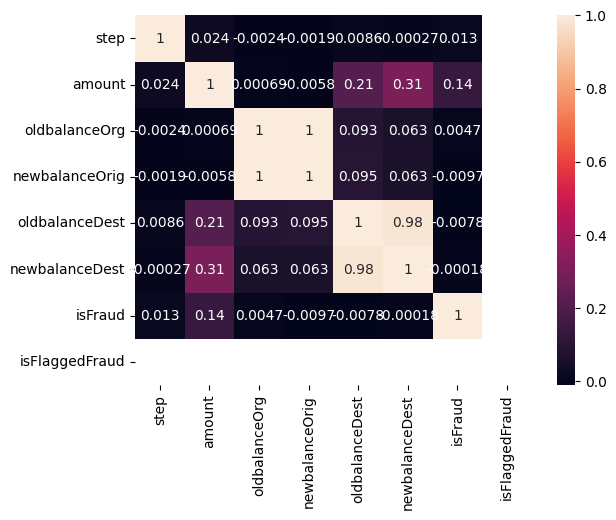

In [14]:
import seaborn as sns

sns.heatmap(
    df.corr(numeric_only=True),
    annot=True
)
plt.show()

In [15]:
threshold = 200000

df['HighAmount'] = (
    df['amount'] > threshold
).astype(int)

df[['amount','HighAmount']].head()

,amount,HighAmount
0,9839.64,0
1,1864.28,0
2,181.00,0
3,181.00,0
4,11668.14,0


 Why threshold = 200,000?

This threshold was chosen to align with the dataset's own business rule:
PaySim's `isFlaggedFraud` column flags any single transfer over 200,000
as suspicious. I used the same cutoff to define a `HighAmount` feature
so the analysis reflects the dataset's built-in logic.

This choice is also supported by the data itself:
- Transactions above 200,000 have a fraud rate of **26.48%**
- Transactions at or below 200,000 have a fraud rate of only 5.96%

This is roughly a 4.4x increase, confirming the threshold meaningfully
separates high-risk from low-risk transactions rather than being an
arbitrary round number.

In [16]:
pd.crosstab(
    df['HighAmount'],
    df['isFraud']
)

isFraud,0.0,1.0
HighAmount,,
0,969650,578
1,372907,990


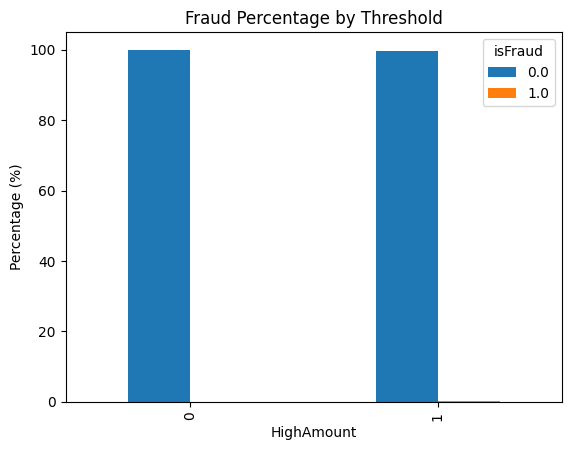

In [17]:
threshold_table = pd.crosstab(
    df['HighAmount'],
    df['isFraud'],
    normalize='index'
) * 100

threshold_table.plot(kind='bar')

plt.title("Fraud Percentage by Threshold")
plt.ylabel("Percentage (%)")
plt.show()

In [18]:
fraud_percentage = (df['isFraud'].sum() / len(df)) * 100

print(f"Fraud Percentage: {fraud_percentage:.4f}%")

Fraud Percentage: 0.1167%


In [19]:
fraud_rate = df.groupby('HighAmount')['isFraud'].mean() * 100

print(fraud_rate)

HighAmount
0    0.059574
1    0.264779
Name: isFraud, dtype: float64


In [20]:
from sklearn.preprocessing import LabelEncoder

encoder = LabelEncoder()

df['type_encoded'] = encoder.fit_transform(df['type'])

In [21]:
df = df.dropna(subset=['isFraud'])

X = df[
    [
        'step',
        'type_encoded',
        'amount',
        'oldbalanceOrg',
        'newbalanceOrig',
        'oldbalanceDest',
        'newbalanceDest'
    ]
]

y = df['isFraud']

print(y.isnull().sum())

0


In [22]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [23]:
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


In [24]:
sample_df = df.sample(n=100000, random_state=42)

print(sample_df.shape)

(100000, 13)


In [25]:
y_pred = model.predict(X_test)

print("Prediction completed!")

Prediction completed!


In [26]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

Accuracy: 0.9997284478750116


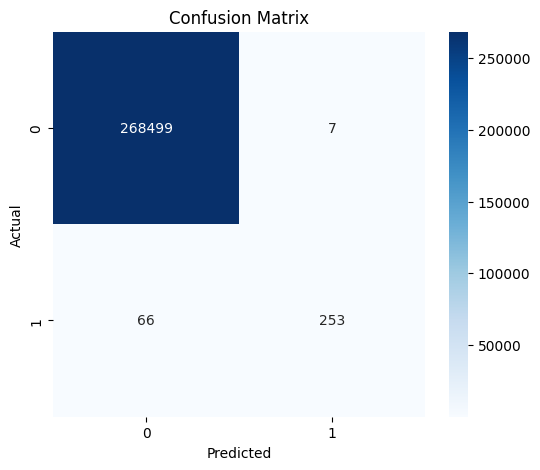

In [27]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')

plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

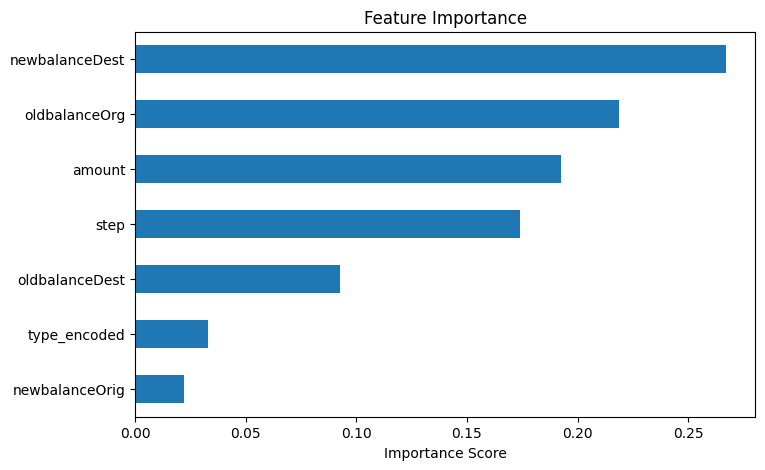

In [28]:
import pandas as pd
import matplotlib.pyplot as plt

importance = pd.Series(
    model.feature_importances_,
    index=X.columns
)

importance.sort_values().plot(
    kind='barh',
    figsize=(8,5)
)

plt.title("Feature Importance")
plt.xlabel("Importance Score")
plt.show()

In [29]:
import joblib
joblib.dump(model, "fraud_model.joblib")
joblib.dump(encoder, "type_encoder.joblib")

['type_encoder.joblib']